# Real Cattle Feed-Intake Prediction — ML Notebook

**Dataset:** Pape et al. (2024), *Dairy cow dry matter intake for multiverse analysis and Bradley-Terry modeling*, Dryad DOI: https://doi.org/10.5061/dryad.sn02v6xbd

**Task:** Predict dry matter intake after 3 hours (`dmi.kg.3h`) using the recorded feed/cow context and early 30-minute intake (`dmi.kg.30mins`).

**Important limitation:** this is a small research dataset: 144 observations from 12 heifers. We use a group split by cow ID so observations from the same cow do not appear in both train and test. Results will be uncertain and should be treated as a proof of concept, not a production-ready cattle model. This predicts intake for this experimental setting; it does not directly predict an animal's daily nutritional requirements.

## 1. Get the real CSV into Kaggle

Download `dairy_cow_dry_matter_intake_for_multiverse_and_bt.csv` from the Dryad dataset page:

https://datadryad.org/dataset/doi:10.5061/dryad.sn02v6xbd

Then add the CSV to a private Kaggle Dataset and attach it to this notebook using **Add Input**. The notebook searches `/kaggle/input` recursively for the exact filename. If the CSV is already attached, continue.

In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import sklearn

RANDOM_STATE = 42
OUT = Path("/kaggle/working/real_cattle_feed_intake_ml")
OUT.mkdir(parents=True, exist_ok=True)

CSV_NAME = "dairy_cow_dry_matter_intake_for_multiverse_and_bt.csv"
matches = list(Path("/kaggle/input").rglob(CSV_NAME)) if Path("/kaggle/input").exists() else []

if not matches:
    print("CSV not found. Attach a Kaggle Dataset containing:", CSV_NAME)
    print("Current input files:")
    for p in Path("/kaggle/input").rglob("*"):
        if p.is_file():
            print(p)
    raise FileNotFoundError(f"Please attach {CSV_NAME} through Kaggle Add Input.")

CSV_PATH = matches[0]
print("Using dataset:", CSV_PATH)
df_raw = pd.read_csv(CSV_PATH)
print("Raw shape:", df_raw.shape)
display(df_raw.head())

Using dataset: /kaggle/input/datasets/shyaamsundar19/dryadd/dairy_cow_dry_matter_intake_for_multiverse_and_bt.csv
Raw shape: (144, 9)


,date,cow.id,trmt,bunk,time,pos,feedout.t.C,dmi.kg.30mins,dmi.kg.3h
0,7/30/2021,3779,A0,A,0,L,19.4,0.9983,1.7662
1,7/30/2021,3854,A0,A,0,R,19.4,0.9471,2.0222
2,7/30/2021,3855,A0,A,0,L,19.4,0.4608,1.0495
3,7/30/2021,3846,A0,A,0,R,19.4,0.7167,1.4335
4,7/30/2021,3843,A0,A,0,L,19.4,1.0495,2.2782


## 2. Inspect and prepare the data

The Dryad documentation describes 144 observations, with each row representing a feed offered to a particular cow on a particular day. Columns include cow ID, feed type, bunk, exposure time, position, feed temperature, and dry matter intake after 30 minutes and 3 hours.

In [2]:
print("Columns:", df_raw.columns.tolist())
print("Shape:", df_raw.shape)
display(df_raw.describe(include="all").T)

# Normalize column names for reliable code use.
df = df_raw.copy()
df.columns = [str(c).strip() for c in df.columns]

required = [
    "cow.id", "trmt", "bunk", "time", "pos", "feedout.t.C",
    "dmi.kg.30mins", "dmi.kg.3h"
]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Expected columns not found: {missing}. Actual columns: {df.columns.tolist()}")

for col in ["time", "feedout.t.C", "dmi.kg.30mins", "dmi.kg.3h"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Missing values by column:")
display(df[required].isna().sum().to_frame("missing"))
print("Unique cows:", df["cow.id"].nunique())
print("Unique feed types:", df["trmt"].nunique())

Columns: ['date', 'cow.id', 'trmt', 'bunk', 'time', 'pos', 'feedout.t.C', 'dmi.kg.30mins', 'dmi.kg.3h']
Shape: (144, 9)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,144,6,7/30/2021,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cow.id,144.0,NaN,NaN,NaN,3839.333333,20.341146,3779.0,3839.5,3845.5,3852.25,3855.0
trmt,144,4,A0,36,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bunk,144,2,A,72,NaN,NaN,NaN,NaN,NaN,NaN,NaN
time,144.0,NaN,NaN,NaN,24.0,24.08377,0.0,0.0,24.0,48.0,48.0
pos,144,2,L,72,NaN,NaN,NaN,NaN,NaN,NaN,NaN
feedout.t.C,144.0,NaN,NaN,NaN,28.125,11.021438,17.1,19.3,22.05,36.925,52.1
dmi.kg.30mins,144.0,NaN,NaN,NaN,0.48369,0.402091,0.0,0.147225,0.36655,0.781525,1.6844
dmi.kg.3h,144.0,NaN,NaN,NaN,0.982056,0.823687,0.0,0.334375,0.7307,1.4925,4.0893


Missing values by column:


,missing
cow.id,0
trmt,0
bunk,0
time,0
pos,0
feedout.t.C,0
dmi.kg.30mins,0
dmi.kg.3h,0


Unique cows: 12
Unique feed types: 4


## 3. Define the prediction task

Target: `dmi.kg.3h` (kg of dry matter consumed after 3 hours).

Features include the measured 30-minute intake, feed type, bunk, exposure time, position, and feed temperature. The 30-minute intake is an early observation available before the 3-hour outcome, so this is an early-intake prediction task.

In [3]:
TARGET = "dmi.kg.3h"
FEATURES = ["trmt", "bunk", "time", "pos", "feedout.t.C", "dmi.kg.30mins"]
GROUP = "cow.id"

model_df = df[FEATURES + [TARGET, GROUP]].dropna().copy()
print("Rows after removing missing target/features:", len(model_df))
print("Unique cows retained:", model_df[GROUP].nunique())
display(model_df.head())

Rows after removing missing target/features: 144
Unique cows retained: 12


,trmt,bunk,time,pos,feedout.t.C,dmi.kg.30mins,dmi.kg.3h,cow.id
0,A0,A,0,L,19.4,0.9983,1.7662,3779
1,A0,A,0,R,19.4,0.9471,2.0222,3854
2,A0,A,0,L,19.4,0.4608,1.0495,3855
3,A0,A,0,R,19.4,0.7167,1.4335,3846
4,A0,A,0,L,19.4,1.0495,2.2782,3843


## 4. Split by cow ID to reduce leakage

A random row split could put observations from the same cow in both training and test data, making evaluation overly optimistic. This notebook holds out entire cows in the test set.

In [4]:
X = model_df[FEATURES]
y = model_df[TARGET]
groups = model_df[GROUP]

splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
groups_train, groups_test = groups.iloc[train_idx], groups.iloc[test_idx]

print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print("Train cows:", sorted(groups_train.unique()))
print("Test cows:", sorted(groups_test.unique()))
assert set(groups_train.unique()).isdisjoint(set(groups_test.unique())), "Cow leakage detected!"

Train rows: 108 | Test rows: 36
Train cows: [np.int64(3825), np.int64(3829), np.int64(3843), np.int64(3844), np.int64(3845), np.int64(3846), np.int64(3847), np.int64(3852), np.int64(3855)]
Test cows: [np.int64(3779), np.int64(3853), np.int64(3854)]


## 5. Train and compare models

We compare:
- Dummy baseline: always predicts the training-set mean.
- Ridge regression: a simple linear baseline.
- Random Forest regression: captures nonlinear relationships.

Because the dataset is small, compare the results rather than assuming Random Forest must win.

In [5]:
categorical = ["trmt", "bunk", "pos"]
numeric = ["time", "feedout.t.C", "dmi.kg.30mins"]

preprocessor = ColumnTransformer([
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical),
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scale", StandardScaler())
    ]), numeric)
])

models = {
    "Dummy mean baseline": DummyRegressor(strategy="mean"),
    "Ridge regression": Pipeline([
        ("prep", preprocessor),
        ("model", Ridge(alpha=1.0))
    ]),
    "Random Forest": Pipeline([
        ("prep", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=300, min_samples_leaf=3,
            max_features=0.8, random_state=RANDOM_STATE
        ))
    ])
}

results = []
fitted_models = {}
predictions = {}

for name, estimator in models.items():
    if name == "Dummy mean baseline":
        estimator.fit(X_train[["dmi.kg.30mins"]], y_train)
        yhat = estimator.predict(X_test[["dmi.kg.30mins"]])
    else:
        estimator.fit(X_train, y_train)
        yhat = estimator.predict(X_test)

    fitted_models[name] = estimator
    predictions[name] = yhat
    results.append({
        "model": name,
        "MAE_kg": mean_absolute_error(y_test, yhat),
        "RMSE_kg": float(np.sqrt(mean_squared_error(y_test, yhat))),
        "R2": r2_score(y_test, yhat)
    })

metrics = pd.DataFrame(results).sort_values("MAE_kg")
display(metrics)
metrics.to_csv(OUT / "model_comparison_metrics.csv", index=False)

,model,MAE_kg,RMSE_kg,R2
1,Ridge regression,0.294534,0.411392,0.777758
2,Random Forest,0.294667,0.394441,0.795696
0,Dummy mean baseline,0.792920,0.926395,-0.126955


## 6. Plot observed vs predicted intake for the best MAE model

Best model by held-out MAE: Ridge regression


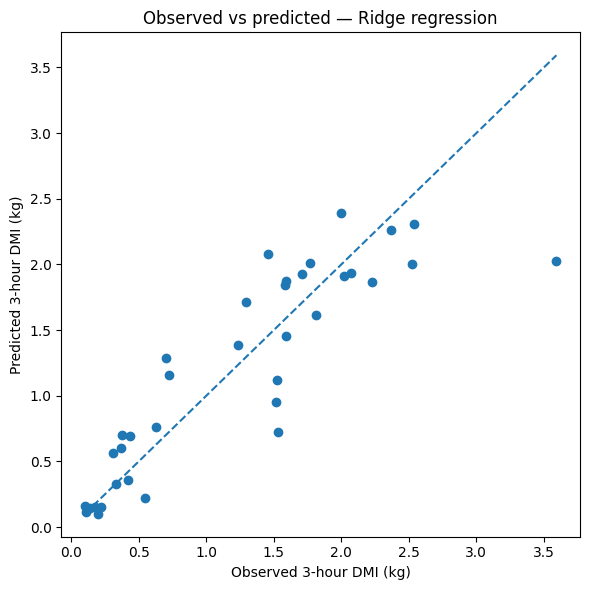

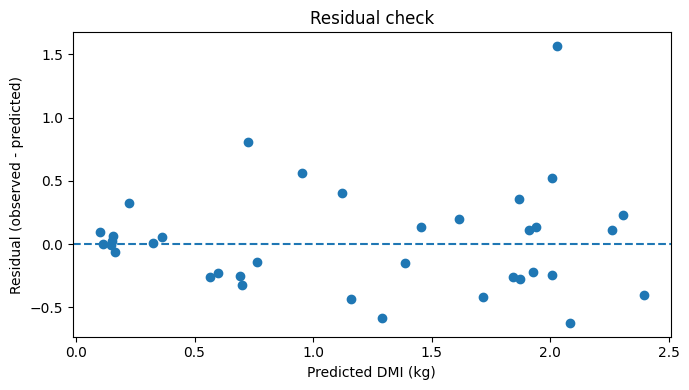

In [6]:
best_name = metrics.iloc[0]["model"]
best_pred = predictions[best_name]
print("Best model by held-out MAE:", best_name)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_pred)
lims = [
    min(float(y_test.min()), float(np.min(best_pred))),
    max(float(y_test.max()), float(np.max(best_pred)))
]
plt.plot(lims, lims, linestyle="--")
plt.xlabel("Observed 3-hour DMI (kg)")
plt.ylabel("Predicted 3-hour DMI (kg)")
plt.title(f"Observed vs predicted — {best_name}")
plt.tight_layout()
plt.show()

residuals = y_test.to_numpy() - best_pred
plt.figure(figsize=(7, 4))
plt.scatter(best_pred, residuals)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted DMI (kg)")
plt.ylabel("Residual (observed - predicted)")
plt.title("Residual check")
plt.tight_layout()
plt.show()

## 7. Save test predictions and the trained model

In [7]:
prediction_output = X_test.copy()
prediction_output["cow_id"] = groups_test.values
prediction_output["observed_dmi_3h_kg"] = y_test.values
prediction_output["predicted_dmi_3h_kg"] = best_pred
prediction_output["absolute_error_kg"] = np.abs(y_test.values - best_pred)
prediction_output.to_csv(OUT / "heldout_cow_predictions.csv", index=False)

# Save the selected model. The Dummy baseline does not need the same feature columns.
selected_model = fitted_models[best_name]
joblib.dump({
    "model_name": best_name,
    "model": selected_model,
    "features": FEATURES,
    "target": TARGET,
    "dataset_doi": "10.5061/dryad.sn02v6xbd",
    "warning": "Small experimental dataset; evaluation is on held-out cows and is not a production-ready model."
}, OUT / "best_feed_intake_model.joblib")

metadata = {
    "dataset": "Dairy cow dry matter intake for multiverse analysis and Bradley-Terry modeling",
    "source": "Dryad",
    "doi": "10.5061/dryad.sn02v6xbd",
    "rows_used": int(len(model_df)),
    "unique_cows": int(model_df[GROUP].nunique()),
    "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "test_cows": [str(x) for x in sorted(groups_test.unique())],
    "target": TARGET,
    "features": FEATURES,
    "split_method": "GroupShuffleSplit by cow.id",
    "python_sklearn_version": sklearn.__version__,
    "limitation": "Only 144 observations from 12 heifers in one experimental setting; results may be unstable and may not generalize to other breeds, farms, or diets."
}
(OUT / "model_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")

print("Saved model and metadata.")
display(prediction_output.head())

Saved model and metadata.


,trmt,bunk,time,pos,feedout.t.C,dmi.kg.30mins,cow_id,observed_dmi_3h_kg,predicted_dmi_3h_kg,absolute_error_kg
0,A0,A,0,L,19.4,0.9983,3779,1.7662,2.007213,0.241013
1,A0,A,0,R,19.4,0.9471,3854,2.0222,1.911655,0.110545
12,B0,B,0,R,19.0,0.0253,3779,0.1011,0.163440,0.062340
13,B0,B,0,L,19.0,0.7584,3854,1.5926,1.455875,0.136725
17,B0,B,0,R,19.0,1.0365,3853,2.0730,1.938308,0.134692


## 8. Export the results ZIP

In [8]:
zip_base = "/kaggle/working/real_cattle_feed_intake_ml_results"
if Path(zip_base + ".zip").exists():
    Path(zip_base + ".zip").unlink()
import shutil
shutil.make_archive(zip_base, "zip", root_dir=OUT)
print("Created:", zip_base + ".zip")
print("Files included:")
for p in sorted(OUT.iterdir()):
    print("-", p.name)

Created: /kaggle/working/real_cattle_feed_intake_ml_results.zip
Files included:
- best_feed_intake_model.joblib
- heldout_cow_predictions.csv
- model_comparison_metrics.csv
- model_metadata.json


In [9]:
from IPython.display import FileLink, display
display(FileLink("/kaggle/working/real_cattle_feed_intake_ml_results.zip"))

/kaggle/working/real_cattle_feed_intake_ml_results.zip

## Dataset citation

Pape, A., Scuderi, R., Green, J., & Ballard, C. (2024). *Dairy cow dry matter intake for multiverse analysis and Bradley-Terry modeling* [Dataset]. Dryad. https://doi.org/10.5061/dryad.sn02v6xbd

The dataset records 144 observations from 12 heifers. Treat this as a small research proof of concept, not as a broadly validated cattle-intake predictor.